In [1]:
import sys
import os

sys.path.append(os.path.abspath(".."))

In [2]:
import torch
import torch.nn as nn

from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader, random_split

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt

In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(device)

cpu


In [4]:
transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor()
])

dataset = datasets.ImageFolder(
    root="../data/images",
    transform=transform
)

In [5]:
train_size = int(0.7 * len(dataset))
val_size = int(0.15 * len(dataset))
test_size = len(dataset) - train_size - val_size

train_dataset, val_dataset, test_dataset = random_split(
    dataset,
    [train_size, val_size, test_size],
    generator=torch.Generator().manual_seed(42)
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False
)

In [6]:
weights = models.MobileNet_V2_Weights.DEFAULT

model = models.mobilenet_v2(weights=weights)

num_classes = len(dataset.classes)

model.classifier[1] = nn.Linear(
    model.classifier[1].in_features,
    num_classes
)

model.load_state_dict(
    torch.load("../models/mobilenetv2_best.pth", map_location=device)
)

model = model.to(device)
model.eval()

print("Model loaded successfully!")

Model loaded successfully!


In [8]:
all_labels = []
all_predictions = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        _, predicted = torch.max(outputs, 1)

        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predicted.cpu().numpy())

print("Testing complete!")

Testing complete!


In [9]:
accuracy = accuracy_score(all_labels, all_predictions)

print(f"Test Accuracy: {accuracy*100:.2f}%")

Test Accuracy: 85.33%


In [11]:
print(
    classification_report(
        all_labels,
        all_predictions,
        target_names=dataset.classes
    )
)

                            precision    recall  f1-score   support

              aerosol_cans       0.89      0.94      0.91        79
        aluminum_food_cans       0.54      0.56      0.55        80
        aluminum_soda_cans       0.81      0.82      0.82        80
           cardboard_boxes       0.46      0.53      0.49        72
       cardboard_packaging       0.54      0.51      0.53        80
                  clothing       0.84      0.92      0.87        72
            coffee_grounds       0.94      0.97      0.95        76
disposable_plastic_cutlery       0.97      0.99      0.98        67
                 eggshells       0.97      0.96      0.96        68
                food_waste       0.95      0.98      0.97        60
    glass_beverage_bottles       0.95      0.95      0.95        91
 glass_cosmetic_containers       0.94      0.94      0.94        65
           glass_food_jars       0.91      0.93      0.92        55
                 magazines       0.89      0.90

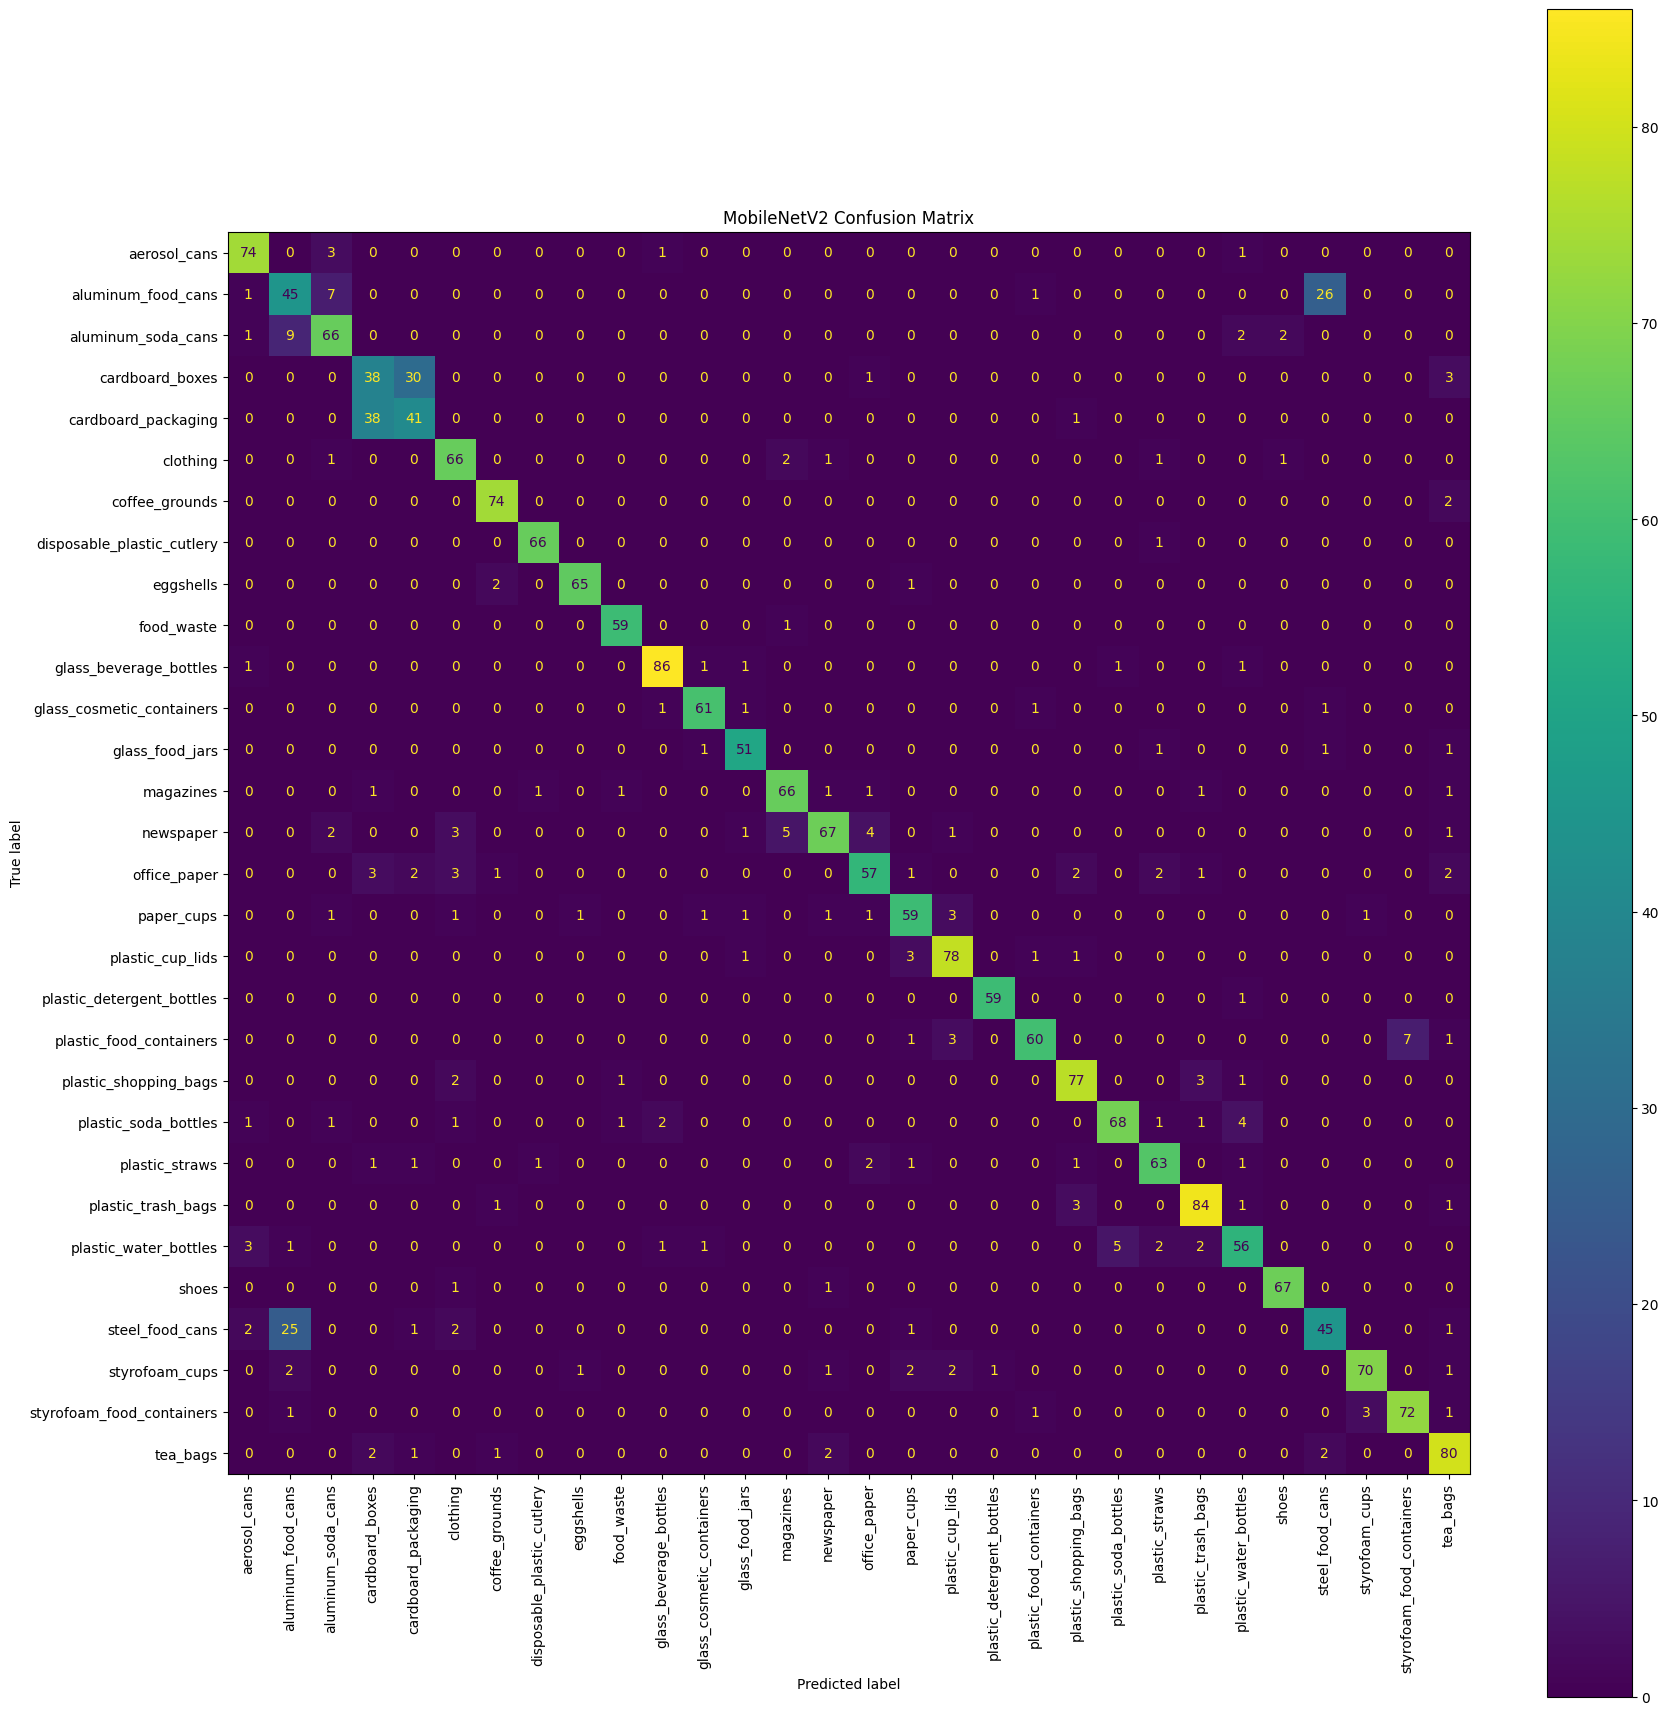

In [12]:
cm = confusion_matrix(all_labels, all_predictions)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=dataset.classes
)

fig, ax = plt.subplots(figsize=(18,18))

disp.plot(ax=ax, xticks_rotation=90)

plt.title("MobileNetV2 Confusion Matrix")

plt.tight_layout()

plt.savefig("../results/mobilenetv2_confusion_matrix.png")

plt.show()

In [13]:
report = classification_report(
    all_labels,
    all_predictions,
    target_names=dataset.classes
)

with open("../results/mobilenetv2_classification_report.txt", "w") as f:
    f.write(report)

print("Classification report saved successfully!")

Classification report saved successfully!
